<a href="https://colab.research.google.com/github/futuregunmulju/2026-Signals-and-Systems-Speech-Noise-Reduction/blob/experiment%2Fminju/Challenge1_Speech_Noise_Reduction_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Google Mount

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
cd /content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge

/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge


# Data Overview

In [3]:
import pandas as pd
from IPython.display import display

datasets = {
    "train": pd.read_csv("train/samples.csv"),
    "validation": pd.read_csv("validation/samples.csv"),
}

for split, df in datasets.items():
    print(f"{split}: {len(df):,}쌍")
    print("컬럼:", ", ".join(df.columns))
    display(df.head(3))

train: 1,296쌍
컬럼: segment_id, clean_path, noisy_path, sample_rate_hz, num_samples, noise_category, noise_collection, noise_code, noise_difficulty, target_snr_db, split


,segment_id,clean_path,noisy_path,sample_rate_hz,num_samples,noise_category,noise_collection,noise_code,noise_difficulty,target_snr_db,split
0,speaker020_utt01_seg0001,train/clean/speaker020_utt01_seg0001.wav,train/noisy/speaker020_utt01_seg0001_noisy.wav,16000,48000,aircraft_cockpit,NOISEX-92,buccaneer1,easy,10.0,train
1,speaker020_utt01_seg0002,train/clean/speaker020_utt01_seg0002.wav,train/noisy/speaker020_utt01_seg0002_noisy.wav,16000,48000,traffic_vehicle,Nonspeech,N046,moderate,15.0,train
2,speaker020_utt01_seg0003,train/clean/speaker020_utt01_seg0003.wav,train/noisy/speaker020_utt01_seg0003_noisy.wav,16000,48000,alarm_siren,Nonspeech,N036,easy,5.0,train


validation: 164쌍
컬럼: segment_id, clean_path, noisy_path, sample_rate_hz, num_samples, noise_category, noise_collection, noise_code, noise_difficulty, target_snr_db, split


,segment_id,clean_path,noisy_path,sample_rate_hz,num_samples,noise_category,noise_collection,noise_code,noise_difficulty,target_snr_db,split
0,speaker015_utt01_seg0001,validation/clean/speaker015_utt01_seg0001.wav,validation/noisy/speaker015_utt01_seg0001_nois...,16000,48000,aircraft_cockpit,NOISEX-92,f16,easy,10.0,validation
1,speaker015_utt01_seg0002,validation/clean/speaker015_utt01_seg0002.wav,validation/noisy/speaker015_utt01_seg0002_nois...,16000,48000,machine,Nonspeech,N026,moderate,15.0,validation
2,speaker015_utt01_seg0003,validation/clean/speaker015_utt01_seg0003.wav,validation/noisy/speaker015_utt01_seg0003_nois...,16000,48000,alarm_siren,Nonspeech,N035,easy,5.0,validation


In [4]:
all_samples = pd.concat(datasets.values(), ignore_index=True)
for column in ("noise_category", "noise_difficulty", "target_snr_db"):
    counts = pd.crosstab(
        all_samples[column].fillna("Missing"),
        all_samples["split"],
    ).reindex(columns=["train", "validation"], fill_value=0)

    percentages = counts.div(counts.sum(axis=0), axis=1).mul(100).round(1)

    print(f"\n{column}")
    display(pd.concat({"Count": counts, "Percent (%)": percentages}, axis=1))

print("Noise categories across both splits:", all_samples["noise_category"].nunique())


noise_category


Count            Percent (%)           
split                train validation       train validation
noise_category                                              
aircraft_cockpit       111         14         8.6        8.5
alarm_siren            187         23        14.4       14.0
animal                  39          2         3.0        1.2
bell                    15          3         1.2        1.8
broadband_noise         73         10         5.6        6.1
clap                     3          1         0.2        0.6
click                    3          1         0.2        0.6
destroyer_engine        36          5         2.8        3.0
destroyer_operations    36          5         2.8        3.0
door_moving              3          1         0.2        0.6
factory                 38          5         2.9        3.0
footsteps                8          1         0.6        0.6
hf_channel              37          4         2.9        2.4
machine                264         34        20.4       20.7
machine_gun              3          1         0.2        0.6
military_vehicle        37          5         2.9        3.0
phone_dialing           43          4         3.3        2.4
shower                   3          1         0.2        0.6
tooth_brushing           3          1         0.2        0.6
traffic_vehicle         76          9         5.9        5.5
vehicle_interior        19          3         1.5        1.8
water                   57          5         4.4        3.0
wind                   202         26        15.6       15.9


noise_difficulty


Count            Percent (%)           
split            train validation       train validation
noise_difficulty                                        
easy               776         99        59.9       60.4
hard               195         24        15.0       14.6
moderate           325         41        25.1       25.0


target_snr_db


Count            Percent (%)           
split         train validation       train validation
target_snr_db                                        
0.0             117         15         9.0        9.1
5.0             298         38        23.0       23.2
10.0            429         55        33.1       33.5
15.0            452         56        34.9       34.1

Noise categories across both splits: 23


In [5]:
# Install PESQ
%pip install -q pesq==0.0.4

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
# Load Validation Data
import numpy as np
import pandas as pd
import soundfile as sf

from IPython.display import Audio, display
from pesq import pesq
from scipy.ndimage import convolve1d
from scipy.signal import stft, istft
from scipy.special import exp1, expit

SR = 16_000
validation = pd.read_csv("validation/samples.csv")

def read_validation_pair(row):
    clean, clean_sr = sf.read(row.clean_path, dtype="float64")
    noisy, noisy_sr = sf.read(row.noisy_path, dtype="float64")

    if clean_sr != SR or noisy_sr != SR:
        raise ValueError(f"{row.segment_id}: expected 16 kHz audio")
    if clean.shape != (48_000,) or noisy.shape != clean.shape:
        raise ValueError(f"{row.segment_id}: expected a 3-second mono pair")

    return clean, noisy

print(f"Validation: {len(validation):,} pairs")

Validation: 164 pairs


# 1. OM-LSA + MCRA
https://www.sciencedirect.com/science/article/abs/pii/S0165168401001281?

In [ ]:
# OM-LSA + MCRA
def denoise_omlsa_mcra(noisy, *, gain_floor_db=-25, alpha_d=0.95, delta=5.0):
    n_fft = 512
    hop = 128
    block_frames = 125
    eps = 1e-12

    _, _, spectrum = stft(
        noisy, fs=SR, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    power = np.abs(spectrum) ** 2
    smoothed_power = convolve1d(power, [0.25, 0.50, 0.25], axis=0)

    # Initialize from the quietest 20% of frames in the first ~0.25 seconds.
    warmup = power[:, 2:-2]
    quiet = np.argsort(warmup.mean(axis=0))[:max(1, warmup.shape[1] // 5)]
    noise_psd = np.maximum(warmup[:, quiet].mean(axis=1), eps)

    smoothed = smoothed_power[:, 0].copy()
    block_min = smoothed.copy()
    previous_block_min = np.full_like(smoothed, np.inf)
    tracking_probability = np.zeros_like(smoothed)
    previous_speech_snr = np.zeros_like(smoothed)
    log_floor = gain_floor_db * np.log(10) / 20
    enhanced_spectrum = np.empty_like(spectrum)

    for t, frame_power in enumerate(power.T):
        # MCRA speech-presence estimate for the noise update.
        smoothed = 0.8 * smoothed + 0.2 * smoothed_power[:, t]
        if t and t % block_frames == 0:
            previous_block_min = block_min
            block_min = smoothed.copy()
        else:
            block_min = np.minimum(block_min, smoothed)

        minimum = np.maximum(np.minimum(previous_block_min, block_min), eps)
        speech_detected = (smoothed > delta * minimum) | (
            frame_power > 1.8 * delta * minimum
        )
        tracking_probability = 0.2 * tracking_probability + 0.8 * speech_detected

        # OM-LSA gain using a fixed prior speech-absence probability of 0.5.
        gamma = np.clip(frame_power / noise_psd, eps, 1000.0)
        xi = 0.92 * previous_speech_snr + 0.08 * np.maximum(gamma - 1, 0)
        xi = np.maximum(xi, 10 ** (-25 / 10))
        ratio = xi / (1 + xi)
        v = gamma * ratio

        log_speech_gain = np.minimum(np.log(ratio) + 0.5 * exp1(v), 0.0)
        speech_probability = expit(v - np.log1p(xi))
        log_gain = speech_probability * log_speech_gain
        log_gain += (1 - speech_probability) * log_floor
        gain = np.exp(np.maximum(log_gain, log_floor))

        enhanced_spectrum[:, t] = gain * spectrum[:, t]
        previous_speech_snr = np.exp(2 * log_speech_gain) * gamma

        # Slow down the noise update when speech is likely present.
        smoothing = alpha_d + (1 - alpha_d) * tracking_probability
        noise_psd = np.maximum(
            smoothing * noise_psd + (1 - smoothing) * frame_power, eps
        )

    _, enhanced = istft(
        enhanced_spectrum, fs=SR, window="hann",
        nperseg=n_fft, noverlap=n_fft - hop,
    )
    return enhanced[:len(noisy)]

In [ ]:
# Listen to One Validation Pair
row = validation.loc[validation["noise_category"].eq("alarm_siren")].iloc[0]
clean, noisy = read_validation_pair(row)
enhanced = denoise_omlsa_mcra(noisy)

print(f"{row.segment_id} | {row.noise_category} | {row.target_snr_db:g} dB")

for label, audio in (("Clean", clean), ("Noisy", noisy), ("Enhanced", enhanced)):
    print(label)
    display(Audio(np.clip(audio, -1, 1), rate=SR, normalize=False))

print(f"Noisy WB-PESQ:    {pesq(SR, clean, noisy, 'wb'):.3f}")
print(f"Enhanced WB-PESQ: {pesq(SR, clean, enhanced, 'wb'):.3f}")

speaker015_utt01_seg0003 | alarm_siren | 5 dB
Clean


Noisy


Enhanced


Noisy WB-PESQ:    1.074
Enhanced WB-PESQ: 1.227


In [ ]:
# Evaluate All Validation Pairs
records = []

for row in validation.itertuples(index=False):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_omlsa_mcra(noisy)

    try:
        noisy_score = pesq(SR, clean, noisy, "wb")
        enhanced_score = pesq(SR, clean, enhanced, "wb")
    except Exception as error:
        raise RuntimeError(f"WB-PESQ failed for {row.segment_id}") from error

    records.append({
        "segment_id": row.segment_id,
        "noise_category": row.noise_category,
        "target_snr_db": row.target_snr_db,
        "Noisy PESQ": noisy_score,
        "Enhanced PESQ": enhanced_score,
        "PESQ Gain": enhanced_score - noisy_score,
    })

results = pd.DataFrame(records)

print(f"Evaluated: {len(results)}/{len(validation)} pairs")
display(results[["Noisy PESQ", "Enhanced PESQ", "PESQ Gain"]]
        .mean().to_frame().T.rename(index={0: "Overall"}).round(3))

def summarize_pesq(column):
    return results.groupby(column).agg(
        Pairs=("segment_id", "size"),
        Noisy_PESQ=("Noisy PESQ", "mean"),
        Enhanced_PESQ=("Enhanced PESQ", "mean"),
        PESQ_Gain=("PESQ Gain", "mean"),
    ).round(3)

display(summarize_pesq("target_snr_db"))
display(summarize_pesq("noise_category").sort_values("Pairs", ascending=False))

Evaluated: 164/164 pairs


,Noisy PESQ,Enhanced PESQ,PESQ Gain
Overall,1.395,1.582,0.187


,Pairs,Noisy_PESQ,Enhanced_PESQ,PESQ_Gain
target_snr_db,,,,
0.0,15,1.080,1.158,0.079
5.0,38,1.218,1.398,0.179
10.0,55,1.358,1.582,0.224
15.0,56,1.635,1.819,0.184


,Pairs,Noisy_PESQ,Enhanced_PESQ,PESQ_Gain
noise_category,,,,
machine,34,1.416,1.591,0.176
wind,26,1.474,1.683,0.210
alarm_siren,23,1.311,1.500,0.189
aircraft_cockpit,14,1.173,1.479,0.305
broadband_noise,10,1.115,1.414,0.299
traffic_vehicle,9,1.525,1.568,0.042
destroyer_engine,5,1.248,1.618,0.370
water,5,1.232,1.227,-0.005
military_vehicle,5,1.421,1.605,0.184


# 2. Generalized Subspace Filter
https://pubmed.ncbi.nlm.nih.gov/25474814/

In [ ]:
from scipy.linalg import eigh
from numpy.lib.stride_tricks import sliding_window_view

def denoise_subspace(noisy, *, mu=1.5):
    order, stride, padding = 32, 8, 16
    frames = sliding_window_view(np.pad(noisy, (padding, padding)), order)[::stride]
    energy = np.mean(frames**2, axis=1)
    window = np.hanning(order + 2)[1:-1]
    identity = np.eye(order)

    output = np.zeros(len(noisy) + 2 * padding)
    weights = np.zeros_like(output)

    for start in range(0, len(frames), 250):
        end = min(start + 250, len(frames))
        lo = max(0, start - 500)
        hi = min(len(frames), end + 500)
        context = frames[lo:hi]

        # 주변 구간에서 에너지가 낮은 프레임으로 잡음 공분산 추정
        quiet_indices = np.argsort(energy[lo:hi])[:max(order, len(context) // 5)]
        quiet = context[quiet_indices]
        noise_cov = quiet.T @ quiet / len(quiet)
        noise_cov += (0.02 * np.trace(noise_cov) / order + 1e-10) * identity
        noisy_cov = context.T @ context / len(context)

        # 잡음 대비 에너지가 큰 성분은 남기고 작은 성분은 감쇠
        eigenvalues, basis = eigh(noisy_cov, noise_cov)
        speech_snr = np.maximum(eigenvalues - 1, 0)
        gain = np.maximum(speech_snr / (speech_snr + mu), 0.12)
        filtered = ((frames[start:end] @ basis) * gain) @ (basis.T @ noise_cov)

        # 겹치는 프레임을 합쳐 파형 복원
        positions = np.arange(start, end) * stride
        for offset, weight in enumerate(window):
            indices = positions + offset
            output[indices] += filtered[:, offset] * weight
            weights[indices] += weight

    output /= np.maximum(weights, 1e-12)
    return output[padding:padding + len(noisy)]

In [ ]:
# 같은 알람 예시로 바로 비교
row = validation.loc[validation["noise_category"].eq("alarm_siren")].iloc[0]
clean, noisy = read_validation_pair(row)

for name, audio in [
    ("Noisy", noisy),
    ("OM-LSA + MCRA", denoise_omlsa_mcra(noisy)),
    ("Subspace", denoise_subspace(noisy)),
]:
    print(f"{name}: {pesq(SR, clean, audio, 'wb'):.3f}")
    display(Audio(audio, rate=SR, normalize=False))


Noisy: 1.074


OM-LSA + MCRA: 1.100


Subspace: 1.208


In [ ]:
# 전체 164쌍과 잡음별 평균 비교
from tqdm.auto import tqdm

subspace_scores = {}

for row in tqdm(validation.itertuples(index=False), total=len(validation)):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_subspace(noisy)
    subspace_scores[row.segment_id] = pesq(SR, clean, enhanced, "wb")

comparison = results.rename(columns={"Enhanced PESQ": "OM-LSA PESQ"}).copy()
comparison["Subspace PESQ"] = comparison["segment_id"].map(subspace_scores)
assert comparison["Subspace PESQ"].notna().all()

columns = ["Noisy PESQ", "OM-LSA PESQ", "Subspace PESQ"]
print(f"평가 완료: {len(comparison)}쌍")
display(comparison[columns].mean().to_frame("전체 평균").T.round(3))
display(comparison.groupby("noise_category")[columns].agg(["mean", "size"]).round(3))

  0%|          | 0/164 [00:00<?, ?it/s]

평가 완료: 164쌍


,Noisy PESQ,OM-LSA PESQ,Subspace PESQ
전체 평균,1.395,1.577,1.486


Noisy PESQ      OM-LSA PESQ      Subspace PESQ     
                           mean size        mean size          mean size
noise_category                                                          
aircraft_cockpit          1.173   14       1.460   14         1.355   14
alarm_siren               1.311   23       1.520   23         1.433   23
animal                    1.423    2       1.327    2         1.461    2
bell                      1.675    3       1.430    3         1.768    3
broadband_noise           1.115   10       1.413   10         1.282   10
clap                      1.378    1       1.261    1         1.421    1
click                     2.129    1       1.860    1         2.282    1
destroyer_engine          1.248    5       1.594    5         1.401    5
destroyer_operations      1.286    5       1.526    5         1.448    5
door_moving               1.777    1       1.670    1         1.772    1
factory                   1.413    5       1.513    5         1.540    5
footsteps                 1.217    1       1.187    1         1.221    1
hf_channel                1.149    4       1.308    4         1.269    4
machine                   1.416   34       1.580   34         1.481   34
machine_gun               2.085    1       1.903    1         2.093    1
military_vehicle          1.421    5       1.613    5         1.466    5
phone_dialing             2.086    4       2.700    4         1.936    4
shower                    1.513    1       2.083    1         1.923    1
tooth_brushing            1.336    1       1.399    1         1.543    1
traffic_vehicle           1.525    9       1.561    9         1.612    9
vehicle_interior          1.861    3       2.109    3         1.849    3
water                     1.232    5       1.215    5         1.412    5
wind                      1.474   26       1.669   26         1.499   26

# 3. TSNR

In [ ]:
import numpy as np
from scipy.signal import stft, istft
from scipy.ndimage import uniform_filter1d
from pesq import pesq
from tqdm.auto import tqdm


def denoise_tsnr(noisy, sr=16000):
    n_fft, hop = 512, 128
    smoothing, gain_floor = 0.98, 0.05

    _, times, spectrum = stft(
        noisy, fs=sr, window="hann",
        nperseg=n_fft, noverlap=n_fft - hop,
    )
    power = np.abs(spectrum) ** 2

    # 양끝의 패딩을 제외하고 에너지가 가장 낮은 20%로 잡음 파워 추정
    centers = np.rint(times * sr).astype(int)
    complete = np.flatnonzero(
        (centers >= n_fft // 2) & (centers + n_fft // 2 <= len(noisy))
    )
    energy = power[:, complete].mean(axis=0)
    count = int(np.ceil(0.20 * len(complete)))
    quiet = complete[np.argsort(energy, kind="stable")[:count]]
    noise_power = power[:, quiet].mean(axis=1)
    noise_power = np.maximum(
        uniform_filter1d(noise_power, size=3, mode="nearest"), 1e-18
    )

    # 1단계. 직전 프레임의 추정치를 이용해 1차 음성 파워 계산
    first_pass_power = np.empty_like(power)
    previous_power = np.zeros_like(noise_power)

    for frame, frame_power in enumerate(power.T):
        instantaneous_snr = np.maximum(frame_power / noise_power - 1, 0)
        prior_snr = instantaneous_snr
        if frame > 0:
            prior_snr = (
                smoothing * previous_power / noise_power
                + (1 - smoothing) * instantaneous_snr
            )

        gain = np.clip(prior_snr / (1 + prior_snr), gain_floor, 1)
        previous_power = np.abs(gain * spectrum[:, frame]) ** 2
        first_pass_power[:, frame] = previous_power

    # 2단계. 현재 프레임의 1차 추정치로 SNR을 다시 계산
    refined_snr = first_pass_power / noise_power[:, None]
    final_gain = np.clip(refined_snr / (1 + refined_snr), gain_floor, 1)

    _, enhanced = istft(
        final_gain * spectrum, fs=sr, window="hann",
        nperseg=n_fft, noverlap=n_fft - hop,
    )
    return enhanced[:len(noisy)]


tsnr_scores = []

for row in tqdm(validation.itertuples(index=False), total=len(validation)):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_tsnr(noisy, SR)
    tsnr_scores.append(pesq(SR, clean, enhanced, "wb"))

mean_pesq = float(np.mean(tsnr_scores))
print(f"TSNR 평균 WB-PESQ ({len(tsnr_scores)}쌍): {mean_pesq:.3f}")
print(f"기존 OM-LSA 1.577 대비: {mean_pesq - 1.577:+.3f}")
print(f"목표 2.300 대비: {mean_pesq - 2.300:+.3f}")

  0%|          | 0/164 [00:00<?, ?it/s]

TSNR 평균 WB-PESQ (164쌍): 1.549
기존 OM-LSA 1.577 대비: -0.028
목표 2.300 대비: -0.751


# 4. Dynamic EQ

In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter, maximum_filter1d, uniform_filter1d
from scipy.signal import stft, istft


def denoise_dynamic_eq(noisy, sr=16000, *, threshold_db=10.0, max_cut_db=12.0):
    n_fft, hop = 1024, 128
    frequencies, _, spectrum = stft(
        noisy, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    magnitude_db = 20 * np.log10(np.maximum(np.abs(spectrum), 1e-12))

    # 양옆 주파수의 중앙값을 기준으로 피크가 얼마나 튀는지 계산
    padded = np.pad(magnitude_db, ((10, 10), (0, 0)), mode="edge")
    sidebands = np.stack([
        padded[10 + offset:10 + offset + len(frequencies)]
        for offset in (*range(-10, -3), *range(4, 11))
    ])
    prominence_db = magnitude_db - np.median(sidebands, axis=0)

    # 알람 후보 대역에서 좁고 지속적인 피크 검출
    target = (
        ((frequencies >= 850) & (frequencies <= 1050))
        | ((frequencies >= 1400) & (frequencies <= 1620))
    )
    local_peak = magnitude_db == maximum_filter1d(magnitude_db, size=5, axis=0)
    candidates = target[:, None] & local_peak & (prominence_db >= threshold_db)

    # 인접 주파수로 조금 이동해도 같은 피크로 보고, 7프레임 중 4개 이상 확인
    nearby = maximum_filter1d(candidates.astype(float), size=5, axis=0)
    persistent = uniform_filter1d(nearby, size=7, axis=1, mode="constant") >= 0.55

    # 피크 주변까지 감쇠하고, 시간·주파수 방향으로 경계를 부드럽게 처리
    cut_db = np.where(candidates & persistent, prominence_db - threshold_db, 0.0)
    cut_db = maximum_filter1d(np.minimum(cut_db, max_cut_db), size=5, axis=0)
    cut_db = gaussian_filter(cut_db, sigma=(0.8, 1.0))
    gain = 10 ** (-cut_db / 20)

    _, enhanced = istft(
        spectrum * gain, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    return enhanced[:len(noisy)]

In [ ]:
import pandas as pd
from IPython.display import display
from pesq import pesq
from tqdm.auto import tqdm

scores = []
for row in tqdm(validation.itertuples(index=False), total=len(validation)):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_dynamic_eq(noisy, sr=SR)

    scores.append({
        "noise_category": row.noise_category,
        "Noisy PESQ": pesq(SR, clean, noisy, "wb"),
        "Dynamic EQ PESQ": pesq(SR, clean, enhanced, "wb"),
    })

eq_results = pd.DataFrame(scores)
eq_results["PESQ 변화"] = eq_results["Dynamic EQ PESQ"] - eq_results["Noisy PESQ"]

metrics = ["Noisy PESQ", "Dynamic EQ PESQ", "PESQ 변화"]
alarm = eq_results.loc[eq_results["noise_category"].eq("alarm_siren")]

display(pd.DataFrame({
    f"전체 ({len(eq_results)}쌍)": eq_results[metrics].mean(),
    f"알람·사이렌 ({len(alarm)}쌍)": alarm[metrics].mean(),
}).T.round(3))

  0%|          | 0/164 [00:00<?, ?it/s]

,Noisy PESQ,Dynamic EQ PESQ,PESQ 변화
전체 (164쌍),1.395,1.383,-0.011
알람·사이렌 (23쌍),1.311,1.318,0.008


# 5. AR-Kalman Filter
https://jeit.ac.cn/en/article/doi/10.11999/JEIT260636

In [ ]:
import numpy as np
from scipy.linalg import solve_toeplitz
from scipy.ndimage import percentile_filter
from scipy.signal import lfilter

try:
    from numba import njit
except ImportError:
    def njit(function):
        return function


@njit
def _kalman_frame(frame, ar, q, r):
    order = len(ar)
    transition = np.zeros((order, order))
    transition[0] = ar
    for j in range(1, order):
        transition[j, j - 1] = 1.0

    state = np.zeros(order)
    covariance = np.eye(order) * (q + r)
    output = np.empty_like(frame)

    for i in range(len(frame)):
        # AR 모델로 다음 음성 샘플과 예측 불확실성을 계산
        state = transition @ state
        covariance = transition @ covariance @ transition.T
        covariance[0, 0] += q

        # 실제 관측값으로 예측 보정. r이 클수록 관측값의 비중이 작아짐
        column = covariance[:, 0].copy()
        innovation_var = covariance[0, 0] + r
        state += (column / innovation_var) * (frame[i] - state[0])
        covariance -= np.outer(column, column) / innovation_var
        output[i] = state[0]

    return output


def denoise_adaptive_ar_kalman(noisy, sr=16000, *, order=12, noise_scale=1.0):
    x = np.asarray(noisy, dtype=np.float64)
    eps = 1e-12
    frame_size = int(0.032 * sr)
    hop = frame_size // 2
    padded = np.pad(x, (hop, hop + (-len(x) % hop)))
    frames = np.lib.stride_tricks.sliding_window_view(padded, frame_size)[::hop]
    window = np.hanning(frame_size + 2)[1:-1]
    window_power = np.sum(window**2)

    # 낮은 에너지 프레임 20%에서 초기 잡음 스펙트럼과 파워 추정
    power = np.abs(np.fft.rfft(frames * window, n=2 * frame_size, axis=1))**2
    energy = (frames**2).mean(axis=1)
    quiet = np.argsort(energy)[:max(1, len(frames) // 5)]
    noise_psd = power[quiet].mean(axis=0)
    noise_energy = max(energy[quiet].mean(), eps)

    # 주변 프레임의 에너지 하한으로 시간에 따른 잡음 크기 반영
    local_floor = percentile_filter(energy, percentile=20, size=31, mode="nearest")
    noise_ratio = np.clip(local_floor / noise_energy, 0.5, 3.0)

    # 에너지가 급증하고 스펙트럼이 평탄한 프레임을 돌발 잡음 후보로 표시
    flatness = np.exp(np.log(power + eps).mean(axis=1)) / (power.mean(axis=1) + eps)
    fast, _ = lfilter([0.5], [1, -0.5], energy, zi=[0.5 * energy[0]])
    slow, _ = lfilter([0.05], [1, -0.95], energy, zi=[0.95 * energy[0]])
    burst = (fast > 2.5 * (slow + eps)) & (flatness > 0.35)

    output = np.zeros_like(padded)
    weights = np.zeros_like(padded)

    for i, frame in enumerate(frames):
        scale = noise_scale * noise_ratio[i]

        # 잡음 파워를 뺀 스펙트럼에서 음성 AR 계수 추정
        speech_psd = np.maximum(power[i] - scale * noise_psd, 0.03 * power[i])
        ac = np.fft.irfft(speech_psd, n=2 * frame_size)[:order + 1]
        ac[0] += 0.01 * ac[0] + eps
        ar = solve_toeplitz(ac[:-1], ac[1:])

        q = max((ac[0] - ar @ ac[1:]) / window_power, eps)
        r = max(scale * noise_energy * (3.0 if burst[i] else 1.0), eps)
        estimate = _kalman_frame(frame.copy(), ar, q, r)

        start = i * hop
        output[start:start + frame_size] += estimate * window
        weights[start:start + frame_size] += window

    return (output / weights)[hop:hop + len(x)]

In [ ]:
import pandas as pd
from IPython.display import display
from pesq import pesq
from tqdm.auto import tqdm

kalman_scores = []

for row in tqdm(validation.itertuples(index=False), total=len(validation)):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_adaptive_ar_kalman(noisy, SR)

    kalman_scores.append({
        "noise_category": row.noise_category,
        "Noisy PESQ": pesq(SR, clean, noisy, "wb"),
        "AR–Kalman PESQ": pesq(SR, clean, enhanced, "wb"),
    })

kalman_results = pd.DataFrame(kalman_scores)
kalman_results["PESQ 변화"] = (
    kalman_results["AR–Kalman PESQ"] - kalman_results["Noisy PESQ"]
)
metrics = ["Noisy PESQ", "AR–Kalman PESQ", "PESQ 변화"]

print(f"전체 평균 ({len(kalman_results)}쌍)")
display(kalman_results[metrics].mean().to_frame().T.round(3))

by_noise = kalman_results.groupby("noise_category")
display(by_noise[metrics].mean().join(by_noise.size().rename("샘플 수")).round(3))

mean_pesq = kalman_results["AR–Kalman PESQ"].mean()
print(f"기존 OM-LSA 1.577 대비: {mean_pesq - 1.577:+.3f}")

  0%|          | 0/164 [00:00<?, ?it/s]

전체 평균 (164쌍)


,Noisy PESQ,AR–Kalman PESQ,PESQ 변화
0,1.395,1.471,0.076


,Noisy PESQ,AR–Kalman PESQ,PESQ 변화,샘플 수
noise_category,,,,
aircraft_cockpit,1.173,1.393,0.220,14
alarm_siren,1.311,1.407,0.096,23
animal,1.423,1.435,0.012,2
bell,1.675,1.518,-0.157,3
broadband_noise,1.115,1.333,0.218,10
clap,1.378,1.324,-0.054,1
click,2.129,2.001,-0.128,1
destroyer_engine,1.248,1.413,0.165,5
destroyer_operations,1.286,1.568,0.282,5


기존 OM-LSA 1.577 대비: -0.106


# 6. OM-LSA + IMCRA

In [ ]:
import numpy as np
from scipy.ndimage import convolve1d
from scipy.signal import stft, istft
from scipy.special import exp1, expit


def denoise_omlsa_imcra(noisy, sr=16000, *, alpha_d=0.95, gain_floor_db=-25):
    n_fft, hop, history = 512, 128, 120
    eps = 1e-12
    _, _, spectrum = stft(
        noisy, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    power = np.abs(spectrum) ** 2
    kernel = [0.25, 0.50, 0.25]
    smoothed_power = convolve1d(power, kernel, axis=0)

    # 기존 OM-LSA와 동일하게 초반 약 0.25초에서 잡음 초기화
    warmup = power[:, 1:33]
    quiet = np.argsort(warmup.mean(axis=0))[:max(1, warmup.shape[1] // 5)]
    noise_psd = np.maximum(warmup[:, quiet].mean(axis=1), eps)

    smooth = smoothed_power[:, 0].copy()
    masked_smooth = smooth.copy()
    first_history = np.full((history, len(smooth)), np.inf)
    second_history = np.full_like(first_history, np.inf)
    previous_speech_snr = np.zeros_like(smooth)
    log_floor = gain_floor_db * np.log(10) / 20
    output = np.empty_like(spectrum)

    for t, frame in enumerate(power.T):
        # IMCRA 1차 추적. 잡음이 우세해 보이는 주파수 성분 선택
        smooth = 0.9 * smooth + 0.1 * smoothed_power[:, t]
        first_history[t % history] = smooth
        first_min = np.maximum(1.66 * first_history.min(axis=0), eps)
        noise_bins = (frame < 4.6 * first_min) & (smooth < 1.67 * first_min)

        # IMCRA 2차 추적. 선택한 성분으로 최솟값과 음성 부재 확률 추정
        weights = convolve1d(noise_bins.astype(float), kernel)
        weighted_power = convolve1d(frame * noise_bins, kernel)
        masked_frame = np.divide(
            weighted_power, weights, out=masked_smooth.copy(), where=weights > 0
        )
        masked_smooth = 0.9 * masked_smooth + 0.1 * masked_frame
        second_history[t % history] = masked_smooth
        second_min = np.maximum(1.66 * second_history.min(axis=0), eps)
        q = np.clip((3.0 - frame / second_min) / 2.0, 0, 1)
        q = np.where(smooth < 1.67 * second_min, q, 0.0)

        # 기존 OM-LSA와 동일한 게인 계산
        gamma = np.clip(frame / noise_psd, eps, 1000.0)
        xi = 0.92 * previous_speech_snr + 0.08 * np.maximum(gamma - 1, 0)
        xi = np.maximum(xi, 10 ** (-25 / 10))
        ratio = xi / (1 + xi)
        v = gamma * ratio
        log_speech_gain = np.minimum(np.log(ratio) + 0.5 * exp1(v), 0)
        speech_probability = expit(v - np.log1p(xi))
        log_gain = speech_probability * log_speech_gain
        log_gain += (1 - speech_probability) * log_floor
        output[:, t] = np.exp(np.maximum(log_gain, log_floor)) * spectrum[:, t]
        previous_speech_snr = np.exp(2 * log_speech_gain) * gamma

        # IMCRA의 음성 존재 확률로 다음 프레임의 잡음 파워 갱신
        likelihood_ratio = (1 + xi) * np.exp(-v)
        p_track = (1 - q) / np.maximum(1 - q + q * likelihood_ratio, eps)
        p_track = np.where(q == 1, 0.0, p_track)
        smoothing = alpha_d + (1 - alpha_d) * p_track
        noise_psd = np.maximum(
            smoothing * noise_psd + (1 - smoothing) * 1.47 * frame, eps
        )

    _, enhanced = istft(
        output, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    return enhanced[:len(noisy)]

In [ ]:
import pandas as pd
from pesq import pesq
from tqdm.auto import tqdm

imcra_records = []

for row in tqdm(validation.itertuples(index=False), total=len(validation)):
    clean, noisy = read_validation_pair(row)
    enhanced = denoise_omlsa_imcra(noisy, SR)
    imcra_records.append({
        "noise_category": row.noise_category,
        "target_snr_db": row.target_snr_db,
        "WB-PESQ": pesq(SR, clean, enhanced, "wb"),
    })

imcra_results = pd.DataFrame(imcra_records)
groups = {
    "전체": imcra_results,
    "알람·사이렌": imcra_results[imcra_results["noise_category"].eq("alarm_siren")],
    "0 dB": imcra_results[imcra_results["target_snr_db"].eq(0)],
}

summary = pd.DataFrame([
    {
        "구간": name,
        "쌍 수": len(group),
        "기존 MCRA": baseline,
        "IMCRA": group["WB-PESQ"].mean(),
    }
    for (name, group), baseline in zip(groups.items(), [1.577, 1.520, 1.161])
]).set_index("구간")

summary["변화"] = summary["IMCRA"] - summary["기존 MCRA"]
display(summary.round(3))

  0%|          | 0/164 [00:00<?, ?it/s]

,쌍 수,기존 MCRA,IMCRA,변화
구간,,,,
전체,164,1.577,1.592,0.015
알람·사이렌,23,1.520,1.554,0.034
0 dB,15,1.161,1.162,0.001


# 7. HPF + Gerkmann MMSE + 2단계 위너/OM-LSA (제미나이)

In [ ]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import butter, sosfiltfilt, stft, istft, medfilt
from scipy.special import exp1
from scipy.ndimage import uniform_filter
from pesq import pesq
from tqdm.auto import tqdm

# 1. 경로 및 메타데이터 로드
BASE_DIR = "/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge"
VAL_CSV = os.path.join(BASE_DIR, "validation", "samples.csv")
val_df = pd.read_csv(VAL_CSV)

# CSV 내 clean / noisy 경로 컬럼 자동 매칭
clean_col = [c for c in val_df.columns if "clean" in c.lower()][0]
noisy_col = [c for c in val_df.columns if "noisy" in c.lower()][0]

def resolve_audio_path(rel_path, split="validation"):
    if os.path.isabs(rel_path) and os.path.exists(rel_path):
        return rel_path
    p1 = os.path.join(BASE_DIR, rel_path)
    if os.path.exists(p1):
        return p1
    return os.path.join(BASE_DIR, split, rel_path)


# 2. 4단계 순수 신호처리 기반 음성 잡음 제거 파이프라인
def denoise_dsp_pipeline(
    noisy,
    sr=16000,
    n_fft=512,
    hop=128,
    hpf_cutoff=150.0,
    alpha_dd=0.98,
    alpha_d=0.85,
    gain_floor_low_db=-13.0,
    gain_floor_high_db=-8.5,
    tonal_thresh=6.0,
):
    orig_len = len(noisy)

    # [Stage 1] Zero-Phase 4차 Butterworth HPF (wind, aircraft, machine 저주파 럼블 제거)
    sos = butter(4, hpf_cutoff, btype="highpass", fs=sr, output="sos")
    x_hp = sosfiltfilt(sos, noisy)

    # STFT 변환
    freqs, _, Zxx = stft(
        x_hp, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    Y_pow = np.abs(Zxx) ** 2 + 1e-12
    F, T = Y_pow.shape

    # [Stage 2] Gerkmann Unbiased MMSE 잡음 PSD 추정 + 협대역 Tonal(alarm_siren) 억제
    frame_energy = np.sum(Y_pow, axis=0)
    init_idx = np.argsort(frame_energy)[: max(5, int(T * 0.15))]
    noise_psd = np.mean(Y_pow[:, init_idx], axis=1)

    noise_psd_mat = np.zeros_like(Y_pow)
    P_bar = np.zeros(F)
    xi_opt = 10.0 ** (15.0 / 10.0)
    q = 0.5
    alpha_p = 0.2
    siren_band = freqs >= 500.0

    for l in range(T):
        y_l = Y_pow[:, l]
        gamma = np.minimum(y_l / (noise_psd + 1e-12), 100.0)

        # 사후 음성 존재 확률 P(H1 | Y)
        bayes = ((1.0 - q) / q) * (1.0 + xi_opt) * np.exp(
            -gamma * xi_opt / (1.0 + xi_opt)
        )
        p_h1 = 1.0 / (1.0 + np.minimum(bayes, 1e12))

        # Stagnation 방지 (Gerkmann et al., 2012)
        P_bar = alpha_p * P_bar + (1.0 - alpha_p) * p_h1
        p_h1 = np.where(P_bar > 0.99, np.minimum(p_h1, 0.99), p_h1)

        # Unbiased MMSE 잡음 추정 업데이트
        n_est = (1.0 - p_h1) * y_l + p_h1 * noise_psd
        noise_psd = alpha_d * noise_psd + (1.0 - alpha_d) * n_est

        # 협대역 사이렌/알람 피크 검출 (주파수 축 1D Median 대비 급격한 스파이크)
        spec_med = medfilt(y_l, kernel_size=15) + 1e-12
        tonal_mask = (y_l / spec_med > tonal_thresh) & siren_band
        if np.any(tonal_mask):
            noise_psd[tonal_mask] = np.maximum(
                noise_psd[tonal_mask], 0.75 * y_l[tonal_mask]
            )

        noise_psd_mat[:, l] = noise_psd

    # [Stage 3-1] 1차 Soft Wiener 프리필터링 (거친 배경 잡음 1차 완화)
    xi_1 = np.maximum(Y_pow / (noise_psd_mat + 1e-12) - 1.0, 0.0)
    G_1 = np.maximum(xi_1 / (xi_1 + 0.6), 0.35)

    Y_pow_2 = (G_1 ** 2) * Y_pow
    noise_psd_2 = (G_1 ** 2) * noise_psd_mat + 1e-12

    # [Stage 3-2] 2차 OM-LSA 필터링 (주파수 대역별 Gain Floor 차등 적용)
    g_min = np.where(
        freqs < 4000.0,
        10.0 ** (gain_floor_low_db / 20.0),
        10.0 ** (gain_floor_high_db / 20.0),
    )
    xi_min = 10.0 ** (-22.0 / 10.0)

    G_2 = np.zeros_like(Y_pow)
    G_prev = np.ones(F)
    gamma_prev = np.ones(F)

    for l in range(T):
        gamma_2 = np.minimum(Y_pow_2[:, l] / noise_psd_2[:, l], 40.0)
        xi_2 = alpha_dd * (G_prev ** 2) * gamma_prev + (1.0 - alpha_dd) * np.maximum(
            gamma_2 - 1.0, 0.0
        )
        xi_2 = np.maximum(xi_2, xi_min)

        v = np.clip((xi_2 / (1.0 + xi_2)) * gamma_2, 1e-10, 50.0)
        G_h1 = (xi_2 / (1.0 + xi_2)) * np.exp(0.5 * exp1(v))

        bayes_2 = ((1.0 - q) / q) * (1.0 + xi_2) * np.exp(-v)
        p_speech = 1.0 / (1.0 + np.minimum(bayes_2, 1e12))

        g_l = (G_h1 ** p_speech) * (g_min ** (1.0 - p_speech))
        g_l = np.clip(g_l, g_min, 1.0)

        G_2[:, l] = g_l
        G_prev = g_l
        gamma_prev = gamma_2

    # [Stage 4] 2D Gain 스무딩으로 Musical Noise 제거 후 역변환
    G_total = uniform_filter(G_1 * G_2, size=(3, 3))
    Zxx_enh = G_total * Zxx

    _, enhanced = istft(
        Zxx_enh, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    enhanced = enhanced[:orig_len]
    if len(enhanced) < orig_len:
        enhanced = np.pad(enhanced, (0, orig_len - len(enhanced)))

    return np.clip(enhanced, -1.0, 1.0)


# 3. Validation 164개 전체 평가 및 카테고리별 분석
noisy_scores = []
enh_scores = []

for _, row in tqdm(val_df.iterrows(), total=len(val_df), desc="Evaluating Validation"):
    clean_path = resolve_audio_path(row[clean_col], "validation")
    noisy_path = resolve_audio_path(row[noisy_col], "validation")

    clean, sr = sf.read(clean_path)
    noisy, _ = sf.read(noisy_path)

    enhanced = denoise_dsp_pipeline(noisy, sr=sr)

    noisy_scores.append(pesq(sr, clean, noisy, "wb"))
    enh_scores.append(pesq(sr, clean, enhanced, "wb"))

val_df["pesq_noisy"] = noisy_scores
val_df["pesq_enh"] = enh_scores
val_df["pesq_gain"] = val_df["pesq_enh"] - val_df["pesq_noisy"]

print(f"\n[전체 Validation 평균 WB-PESQ (N={len(val_df)})]")
print(f"- Noisy Baseline : {val_df['pesq_noisy'].mean():.4f}")
print(f"- DSP Enhanced   : {val_df['pesq_enh'].mean():.4f} (+{val_df['pesq_gain'].mean():.4f})")

print("\n[소음 카테고리별 평균 WB-PESQ]")
print(
    val_df.groupby("noise_category")[["pesq_noisy", "pesq_enh", "pesq_gain"]]
    .mean()
    .sort_values("pesq_enh")
    .round(4)
)

print("\n[SNR / 난이도별 평균 WB-PESQ]")
print(val_df.groupby("target_snr_db")[["pesq_noisy", "pesq_enh", "pesq_gain"]].mean().round(4))
print(val_df.groupby("noise_difficulty")[["pesq_noisy", "pesq_enh", "pesq_gain"]].mean().round(4))

Evaluating Validation:   0%|          | 0/164 [00:00<?, ?it/s]


[전체 Validation 평균 WB-PESQ (N=164)]
- Noisy Baseline : 1.3947
- DSP Enhanced   : 1.3869 (+-0.0077)

[소음 카테고리별 평균 WB-PESQ]
                      pesq_noisy  pesq_enh  pesq_gain
noise_category                                       
hf_channel                1.1492    1.1139    -0.0353
broadband_noise           1.1153    1.1408     0.0256
footsteps                 1.2168    1.1471    -0.0697
water                     1.2317    1.1887    -0.0431
clap                      1.3776    1.2143    -0.1634
aircraft_cockpit          1.1731    1.2349     0.0618
destroyer_engine          1.2479    1.2465    -0.0015
destroyer_operations      1.2859    1.2932     0.0073
alarm_siren               1.3106    1.3211     0.0105
animal                    1.4230    1.3405    -0.0825
tooth_brushing            1.3356    1.3717     0.0361
door_moving               1.7771    1.3937    -0.3834
click                     2.1288    1.4010    -0.7279
factory                   1.4133    1.4059    -0.0074
machine       

In [ ]:
import os
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import butter, sosfiltfilt, stft, istft
from scipy.ndimage import minimum_filter1d, median_filter, convolve1d
from pesq import pesq
from tqdm.auto import tqdm

BASE_DIR = "/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge"
VAL_CSV = os.path.join(BASE_DIR, "validation", "samples.csv")
if "val_df" not in globals():
    val_df = pd.read_csv(VAL_CSV)

clean_col = [c for c in val_df.columns if "clean" in c.lower()][0]
noisy_col = [c for c in val_df.columns if "noisy" in c.lower()][0]

def resolve_audio_path(rel_path, split="validation"):
    if os.path.isabs(rel_path) and os.path.exists(rel_path):
        return rel_path
    p1 = os.path.join(BASE_DIR, rel_path)
    return p1 if os.path.exists(p1) else os.path.join(BASE_DIR, split, rel_path)


def denoise_tsnr_hrnr(
    noisy,
    sr=16000,
    n_fft=512,
    hop=128,
    hpf_cutoff=75.0,
    alpha_dd=0.92,
    bias_comp=1.65,
):
    orig_len = len(noisy)

    # [1] 75Hz 2차 HPF (음성 기본주파수 보존, 초저주파 럼블만 제거)
    sos = butter(2, hpf_cutoff, btype="highpass", fs=sr, output="sos")
    x_hp = sosfiltfilt(sos, noisy)

    freqs, _, Zxx = stft(
        x_hp, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    mag = np.abs(Zxx)
    phase = np.angle(Zxx)
    Y_pow = mag ** 2 + 1e-12
    F, T = Y_pow.shape

    # [2] 임펄스 잡음(click, door_moving, clap) 검출 및 프레임 보간
    frame_energy = np.sum(Y_pow, axis=0)
    geo_mean = np.exp(np.mean(np.log(Y_pow), axis=0))
    arith_mean = np.mean(Y_pow, axis=0)
    flatness = geo_mean / (arith_mean + 1e-12)  # 광대역 클릭은 평탄도가 높음

    local_med_e = median_filter(frame_energy, size=11) + 1e-12
    is_impulse = (frame_energy > 3.5 * local_med_e) & (flatness > 0.22)

    # 1~3프레임 이하의 짧은 비음성 클릭만 인접 프레임 크기로 선형 보간
    t = 0
    while t < T:
        if is_impulse[t]:
            end = t
            while end < T and is_impulse[end]:
                end += 1
            if (end - t) <= 3 and t > 0 and end < T:
                left_mag = mag[:, t - 1 : t]
                right_mag = mag[:, end : end + 1]
                alphas = np.linspace(0, 1, end - t + 2)[1:-1][None, :]
                mag[:, t:end] = (1.0 - alphas) * left_mag + alphas * right_mag
            t = end
        else:
            t += 1

    Y_pow = mag ** 2 + 1e-12
    Zxx = mag * np.exp(1j * phase)

    # [3] 편향 보정 최소값 추적(Minimum Statistics) + 협대역 사이렌 억제
    Y_time_smooth = convolve1d(Y_pow, weights=[0.2, 0.3, 0.3, 0.2], axis=1, mode="nearest")
    win_len = min(T, int(0.65 * sr / hop))  # 약 0.65초 슬라이딩 윈도우
    noise_min = minimum_filter1d(Y_time_smooth, size=max(15, win_len), axis=1, mode="nearest")
    noise_psd = bias_comp * noise_min

    # 협대역 사이렌/벨 피크 억제 (주파수축 1D Median 대비 돌출된 톤)
    spec_med = median_filter(Y_pow, size=(17, 1)) + 1e-12
    siren_mask = (Y_pow / spec_med > 7.5) & (freqs[:, None] >= 450.0)
    noise_psd = np.where(siren_mask, np.maximum(noise_psd, 0.8 * Y_pow), noise_psd)

    # 전체 추정 SNR에 따른 적응형 Gain Floor (15dB 고SNR 음성 손상 방지)
    est_snr_db = 10.0 * np.log10(
        max(np.mean(Y_pow) - np.mean(noise_psd), 1e-8) / (np.mean(noise_psd) + 1e-12)
    )
    floor_db = np.clip(-15.5 + 0.55 * max(est_snr_db, 0.0), -15.5, -6.5)
    g_min = 10.0 ** (floor_db / 20.0)

    # [4] TSNR (Two-Step Noise Reduction) - 1프레임 지연 없는 사전 SNR 추정
    G_dd = np.zeros_like(Y_pow)
    G_prev = np.ones(F)
    gamma_prev = np.ones(F)

    for l in range(T):
        gamma = np.minimum(Y_pow[:, l] / (noise_psd[:, l] + 1e-12), 50.0)
        xi_dd = alpha_dd * (G_prev ** 2) * gamma_prev + (1.0 - alpha_dd) * np.maximum(gamma - 1.0, 0.0)
        g_l = np.clip(xi_dd / (xi_dd + 1.0), g_min, 1.0)
        G_dd[:, l] = g_l
        G_prev = g_l
        gamma_prev = gamma

    # 2단계: 지연 제거된 사전 SNR 및 TSNR 이득 산출
    xi_tsnr = ((G_dd ** 2) * Y_pow) / (noise_psd + 1e-12)
    G_tsnr = np.clip(xi_tsnr / (xi_tsnr + 1.0), g_min, 1.0)

    # [5] HRNR (Harmonic Regeneration Noise Reduction) - 손실된 배음 복원
    _, s_tsnr = istft(G_tsnr * Zxx, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    s_harm = np.maximum(s_tsnr, 0.0)  # 반파 정류로 배음 성분 생성
    _, S_harm_stft = stft(s_harm, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    S_harm_pow = np.abs(S_harm_stft[:, :T]) ** 2

    rho = G_tsnr
    xi_hrnr = (rho * (G_tsnr ** 2) * Y_pow + (1.0 - rho) * S_harm_pow) / (noise_psd + 1e-12)
    G_final = np.clip(xi_hrnr / (xi_hrnr + 1.0), g_min, 1.0)

    # 주파수 축으로만 얇게 스무딩 (시간축 번짐 방지)
    G_final = convolve1d(G_final, weights=[0.2, 0.6, 0.2], axis=0, mode="nearest")

    _, enhanced = istft(
        G_final * Zxx, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop
    )
    enhanced = enhanced[:orig_len]
    if len(enhanced) < orig_len:
        enhanced = np.pad(enhanced, (0, orig_len - len(enhanced)))

    return np.clip(enhanced, -1.0, 1.0)


# Validation 전체 평가 (기존 pesq_noisy가 있으면 재사용해 속도 2배 단축)
need_noisy = "pesq_noisy" not in val_df.columns
noisy_scores = []
enh_scores = []

for _, row in tqdm(val_df.iterrows(), total=len(val_df), desc="Evaluating TSNR+HRNR"):
    clean, sr = sf.read(resolve_audio_path(row[clean_col], "validation"))
    noisy, _ = sf.read(resolve_audio_path(row[noisy_col], "validation"))

    enhanced = denoise_tsnr_hrnr(noisy, sr=sr)

    if need_noisy:
        noisy_scores.append(pesq(sr, clean, noisy, "wb"))
    enh_scores.append(pesq(sr, clean, enhanced, "wb"))

if need_noisy:
    val_df["pesq_noisy"] = noisy_scores
val_df["pesq_enh"] = enh_scores
val_df["pesq_gain"] = val_df["pesq_enh"] - val_df["pesq_noisy"]

print(f"\n[전체 Validation 평균 WB-PESQ (N={len(val_df)})]")
print(f"- Noisy Baseline : {val_df['pesq_noisy'].mean():.4f}")
print(f"- TSNR+HRNR Enh  : {val_df['pesq_enh'].mean():.4f} ({val_df['pesq_gain'].mean():+.4f})")

print("\n[소음 카테고리별 평균 WB-PESQ]")
print(
    val_df.groupby("noise_category")[["pesq_noisy", "pesq_enh", "pesq_gain"]]
    .mean()
    .sort_values("pesq_enh")
    .round(4)
)

print("\n[SNR별 평균 WB-PESQ]")
print(val_df.groupby("target_snr_db")[["pesq_noisy", "pesq_enh", "pesq_gain"]].mean().round(4))

Evaluating TSNR+HRNR:   0%|          | 0/164 [00:00<?, ?it/s]

ValueError: too many values to unpack (expected 2)

# 8. Cascade: 비인과 잡음추정 + LSA/TSNR + 톤성 억제 (클로드)

In [ ]:
%%writefile denoise.py
"""Cascade speech denoiser (classical DSP only, no ML).

Stage 0 : zero-phase high-pass (wind / rumble)
Stage 1 : sweeping-tone (siren/alarm) suppression, optional
Stage 2 : two-pass NON-CAUSAL noise PSD estimation over the whole clip
Stage 3 : decision-directed MMSE-LSA gain
Stage 4 : TSNR refinement (Plapous et al., 2006)
Stage 5 : musical-noise suppression (gain smoothing in low-gain regions)
Stage 6 : optional leak of the high-passed noisy signal

CLI:  python denoise.py --input_dir input --output_dir output
"""
import argparse
import json
import os

import numpy as np
import soundfile as sf
from scipy.ndimage import gaussian_filter1d, minimum_filter1d, uniform_filter, uniform_filter1d
from scipy.signal import butter, istft, sosfiltfilt, stft
from scipy.special import exp1

DEFAULTS = dict(
    hp_hz=60.0,
    n_fft=512, hop=128,
    min_win=120,
    min_bias=1.7,
    delta=3.0,
    noise_sigma=40.0,
    noise_scale=1.1,
    n_iter=2,
    alpha_dd=0.96,
    gain_floor_db=-18.0,
    tsnr=True,
    gain_smooth=True,
    leak=0.0,
    tonal_db=0.0,          # 0 = off
    tonal_max_cut_db=20.0,
    tonal_max_peaks=5,
)

# 튜닝 결과(best_params.json)가 이 파일 옆에 있으면 자동으로 기본값에 반영
_CFG = os.path.join(os.path.dirname(os.path.abspath(__file__)), "best_params.json")
if os.path.exists(_CFG):
    DEFAULTS.update(json.load(open(_CFG)))


def _noise_psd(P, p):
    S = uniform_filter1d(P, 3, axis=0, mode="nearest")
    S = uniform_filter1d(S, 5, axis=1, mode="nearest")
    win = int(min(p["min_win"], P.shape[1]))
    n_min = minimum_filter1d(S, size=win, axis=1, mode="nearest") * p["min_bias"]
    n_min = np.maximum(gaussian_filter1d(n_min, 5, axis=1, mode="nearest"), 1e-14)

    noise = n_min.copy()
    for _ in range(int(p["n_iter"])):
        speech = (S > p["delta"] * noise).astype(float)
        presence = uniform_filter(speech, size=(3, 5), mode="nearest")
        w = (1.0 - presence) ** 2
        num = gaussian_filter1d(w * P, p["noise_sigma"], axis=1, mode="nearest")
        den = gaussian_filter1d(w, p["noise_sigma"], axis=1, mode="nearest")
        lam = np.clip(den / 0.3, 0.0, 1.0)
        avg = num / np.maximum(den, 1e-9)
        noise = np.maximum(lam * avg + (1 - lam) * n_min, 1e-14)
    return noise * p["noise_scale"]


def _tonal_suppress(x, sr, thr_db, max_cut_db, max_peaks):
    """Sparse, prominent, time-continuous spectral peaks (siren/alarm, also sweeping)
    are notched out. Voiced speech has many harmonic peaks per frame -> protected."""
    n_fft, hop = 1024, 128
    _, _, Y = stft(x, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    mag_db = 20 * np.log10(np.abs(Y) + 1e-9)
    K, T = mag_db.shape
    pad = np.pad(mag_db, ((24, 24), (0, 0)), mode="edge")
    offs = [*range(-24, -5), *range(6, 25)]
    side = np.median(np.stack([pad[24 + o:24 + o + K] for o in offs]), axis=0)
    prom = mag_db - side
    peak = (mag_db >= np.roll(mag_db, 1, 0)) & (mag_db >= np.roll(mag_db, -1, 0)) & (prom >= thr_db)
    peak[:4] = False
    sparse = peak.sum(axis=0) <= max_peaks
    peak &= sparse[None, :]
    near = uniform_filter(peak.astype(float), size=(7, 1), mode="constant") > 0
    persistent = uniform_filter1d(near.astype(float), size=5, axis=1, mode="constant") >= 0.6
    cand = peak & persistent
    cut = np.where(cand, np.minimum(prom - thr_db + 6.0, max_cut_db), 0.0)
    cut = uniform_filter(cut, size=(5, 1), mode="constant") * 1.5
    cut = np.minimum(gaussian_filter1d(cut, 1.0, axis=1), max_cut_db)
    _, y = istft(Y * 10 ** (-cut / 20), fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    y = y[:len(x)]
    return np.pad(y, (0, len(x) - len(y))) if len(y) < len(x) else y


def _lsa(xi, gamma):
    r = xi / (1.0 + xi)
    v = np.maximum(r * gamma, 1e-8)
    return r * np.exp(0.5 * exp1(v))


def denoise_channel(x, sr=16000, **overrides):
    p = {**DEFAULTS, **overrides}
    x = np.asarray(x, dtype=np.float64)
    n = len(x)
    if n < p["n_fft"] or not np.any(x):
        return x.copy()

    if p["hp_hz"] > 0:
        sos = butter(4, p["hp_hz"], btype="highpass", fs=sr, output="sos")
        xh = sosfiltfilt(sos, x)
    else:
        xh = x

    if p["tonal_db"] > 0:
        xh = _tonal_suppress(xh, sr, p["tonal_db"], p["tonal_max_cut_db"], int(p["tonal_max_peaks"]))

    n_fft, hop = int(p["n_fft"]), int(p["hop"])
    _, _, Y = stft(xh, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    P = np.abs(Y) ** 2 + 1e-14
    N = _noise_psd(P, p)

    floor = 10 ** (p["gain_floor_db"] / 20)
    K, T = P.shape
    G = np.empty_like(P)
    prev = np.zeros(K)
    xi_min = 10 ** (-25 / 10)
    for t in range(T):
        gamma = np.minimum(P[:, t] / N[:, t], 1000.0)
        xi = np.maximum(p["alpha_dd"] * prev + (1 - p["alpha_dd"]) * np.maximum(gamma - 1, 0), xi_min)
        g = np.clip(_lsa(xi, gamma), floor, 1.0)
        G[:, t] = g
        prev = g ** 2 * gamma

    if p["tsnr"]:
        xi2 = G ** 2 * P / N
        G = np.clip(xi2 / (1.0 + xi2), floor, 1.0)

    if p["gain_smooth"]:
        Gs = uniform_filter(G, size=(3, 3), mode="nearest")
        G = np.where(G < 0.4, Gs, G)

    _, y = istft(Y * G, fs=sr, window="hann", nperseg=n_fft, noverlap=n_fft - hop)
    y = y[:n]
    if len(y) < n:
        y = np.pad(y, (0, n - len(y)))
    if p["leak"] > 0:
        y = y + p["leak"] * xh
    return np.nan_to_num(y)


def denoise(x, sr=16000, **overrides):
    x = np.asarray(x, dtype=np.float64)
    if x.ndim == 1:
        return denoise_channel(x, sr, **overrides)
    return np.stack([denoise_channel(x[:, c], sr, **overrides) for c in range(x.shape[1])], axis=1)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input_dir", default="input")
    ap.add_argument("--output_dir", default="output")
    args = ap.parse_args()
    os.makedirs(args.output_dir, exist_ok=True)
    for name in sorted(os.listdir(args.input_dir)):
        if not name.lower().endswith(".wav"):
            continue
        src = os.path.join(args.input_dir, name)
        x, sr = sf.read(src, dtype="float64")
        y = np.clip(denoise(x, sr), -1.0, 1.0)
        assert y.shape == x.shape, (name, y.shape, x.shape)
        sf.write(os.path.join(args.output_dir, name), y, sr, subtype=sf.info(src).subtype)


if __name__ == "__main__":
    main()

Writing denoise.py


In [ ]:
import importlib, denoise as dn
from tqdm.auto import tqdm
importlib.reload(dn)

def snr_db(ref, x):
    return 10 * np.log10(np.sum(ref**2) / max(np.sum((ref - x)**2), 1e-12))

def safe_pesq(ref, deg):
    try:
        return pesq(SR, ref, deg, "wb")
    except Exception:
        return 1.04  # 무음 출력 등 PESQ 실패 시 최저점 처리

def eval_cascade(params=None, rows=validation, verbose=True):
    params = params or {}
    recs = []
    for row in tqdm(rows.itertuples(index=False), total=len(rows), disable=not verbose):
        clean, noisy = read_validation_pair(row)
        enh = np.clip(dn.denoise(noisy, SR, **params), -1, 1)
        recs.append({
            "noise_category": row.noise_category, "target_snr_db": row.target_snr_db,
            "Noisy PESQ": safe_pesq(clean, noisy), "PESQ": safe_pesq(clean, enh),
            "Noisy SNR": snr_db(clean, noisy), "SNR": snr_db(clean, enh),
        })
    return pd.DataFrame(recs)

cas = eval_cascade()
cas["PESQ Gain"] = cas["PESQ"] - cas["Noisy PESQ"]
print(f"Cascade 평균 WB-PESQ: {cas['PESQ'].mean():.3f} "
      f"(기존 최고 IMCRA 1.592 대비 {cas['PESQ'].mean() - 1.592:+.3f}) | "
      f"SNR {cas['Noisy SNR'].mean():.2f} → {cas['SNR'].mean():.2f} dB")
display(cas.groupby("target_snr_db")[["Noisy PESQ", "PESQ", "PESQ Gain", "SNR"]].mean().round(3))
g = cas.groupby("noise_category")
display(g[["Noisy PESQ", "PESQ", "PESQ Gain"]].mean()
        .join(g.size().rename("Pairs")).sort_values("Pairs", ascending=False).round(3))

  0%|          | 0/164 [00:00<?, ?it/s]

Cascade 평균 WB-PESQ: 1.687 (기존 최고 IMCRA 1.592 대비 +0.095) | SNR 9.63 → 12.90 dB


,Noisy PESQ,PESQ,PESQ Gain,SNR
target_snr_db,,,,
0.0,1.080,1.195,0.116,6.411
5.0,1.218,1.476,0.258,10.777
10.0,1.358,1.675,0.318,13.294
15.0,1.635,1.973,0.338,15.685


,Noisy PESQ,PESQ,PESQ Gain,Pairs
noise_category,,,,
machine,1.416,1.633,0.218,34
wind,1.474,1.860,0.386,26
alarm_siren,1.311,1.549,0.238,23
aircraft_cockpit,1.173,1.532,0.359,14
broadband_noise,1.115,1.532,0.417,10
traffic_vehicle,1.525,1.677,0.152,9
destroyer_engine,1.248,1.734,0.486,5
water,1.232,1.285,0.053,5
military_vehicle,1.421,1.687,0.266,5


In [ ]:
import os, json
from multiprocessing import Pool

N_TRAIN, N_TRIALS, SEED = 160, 40, 0
train = pd.read_csv("train/samples.csv")
sub = train.sample(N_TRAIN, random_state=SEED).reset_index(drop=True)
PAIRS = [(sf.read(r.clean_path)[0], sf.read(r.noisy_path)[0]) for r in sub.itertuples()]

SPACE = dict(
    hp_hz=[0, 40, 60, 80, 100, 130], n_fft=[320, 400, 512, 640], min_win=[60, 90, 120, 160],
    min_bias=(1.2, 2.2), delta=(2.0, 5.0), noise_sigma=(15, 80), noise_scale=(0.9, 1.5),
    n_iter=[1, 2, 3], alpha_dd=(0.90, 0.985), gain_floor_db=(-28, -8),
    tsnr=[True, False], gain_smooth=[True, False], leak=(0.0, 0.2),
    tonal_db=[0, 0, 11, 13, 15, 18],
)

def sample_params(rng):
    p = dict(dn.DEFAULTS)
    for k, v in SPACE.items():
        p[k] = v[rng.integers(len(v))] if isinstance(v, list) else float(rng.uniform(*v))
    p["n_fft"] = int(p["n_fft"]); p["hop"] = p["n_fft"] // 4
    p["min_win"] = int(p["min_win"]); p["n_iter"] = int(p["n_iter"])
    p["hp_hz"] = float(p["hp_hz"]); p["tonal_db"] = float(p["tonal_db"])
    p["tsnr"] = bool(p["tsnr"]); p["gain_smooth"] = bool(p["gain_smooth"])
    return p

def _score(args):
    i, params = args
    clean, noisy = PAIRS[i]
    out = np.clip(dn.denoise(noisy, SR, **params), -1, 1)
    return safe_pesq(clean, out)

def eval_train(params, pool):
    return float(np.mean(pool.map(_score, [(i, params) for i in range(len(PAIRS))])))

rng = np.random.default_rng(SEED)
trials = []
with Pool(os.cpu_count()) as pool:          # PAIRS 정의 후에 Pool을 만들어야 워커가 데이터를 상속
    base = eval_train(dict(dn.DEFAULTS), pool)
    trials.append((base, dict(dn.DEFAULTS)))
    print(f"기본값 Train-subset PESQ = {base:.4f}")
    for t in range(N_TRIALS):
        p = sample_params(rng)
        s = eval_train(p, pool)
        trials.append((s, p))
        print(f"trial {t+1:3d}: {s:.4f} | best {max(x[0] for x in trials):.4f}", flush=True)

trials.sort(key=lambda x: -x[0])
top = trials[:3]
print("\nTop3 Train-subset 점수:", [round(s, 4) for s, _ in top])

기본값 Train-subset PESQ = 1.7141
trial   1: 1.7288 | best 1.7288
trial   2: 1.7387 | best 1.7387
trial   3: 1.6017 | best 1.7387
trial   4: 1.6968 | best 1.7387
trial   5: 1.6815 | best 1.7387
trial   6: 1.5868 | best 1.7387
trial   7: 1.7195 | best 1.7387
trial   8: 1.6534 | best 1.7387
trial   9: 1.5926 | best 1.7387
trial  10: 1.7866 | best 1.7866
trial  11: 1.6941 | best 1.7866
trial  12: 1.7724 | best 1.7866
trial  13: 1.7061 | best 1.7866
trial  14: 1.8367 | best 1.8367
trial  15: 1.7006 | best 1.8367
trial  16: 1.7019 | best 1.8367
trial  17: 1.6372 | best 1.8367
trial  18: 1.8170 | best 1.8367
trial  19: 1.7209 | best 1.8367
trial  20: 1.7619 | best 1.8367
trial  21: 1.6714 | best 1.8367
trial  22: 1.7081 | best 1.8367
trial  23: 1.7318 | best 1.8367
trial  24: 1.6888 | best 1.8367
trial  25: 1.7222 | best 1.8367
trial  26: 1.7221 | best 1.8367
trial  27: 1.6768 | best 1.8367
trial  28: 1.6438 | best 1.8367
trial  29: 1.6253 | best 1.8367
trial  30: 1.6487 | best 1.8367
trial  31

In [ ]:
best = None
for s_tr, p in top:
    v = eval_cascade(p, verbose=False)["PESQ"].mean()
    print(f"Train {s_tr:.4f} | Validation {v:.4f}")
    if best is None or v > best[0]:
        best = (v, p)

print(f"\n선택: Validation WB-PESQ = {best[0]:.4f}")
json.dump(best[1], open("best_params.json", "w"), indent=2, default=lambda o: o.item())
print(json.dumps(best[1], indent=2, default=lambda o: o.item()))

importlib.reload(dn)   # best_params.json을 DEFAULTS에 반영
cas = eval_cascade()
cas["PESQ Gain"] = cas["PESQ"] - cas["Noisy PESQ"]
print(f"\n최종 평균 WB-PESQ {cas['PESQ'].mean():.3f}, SNR {cas['Noisy SNR'].mean():.2f} → {cas['SNR'].mean():.2f} dB")
display(cas.groupby("target_snr_db")[["Noisy PESQ", "PESQ", "PESQ Gain", "SNR"]].mean().round(3))
g = cas.groupby("noise_category")
display(g[["Noisy PESQ", "PESQ", "PESQ Gain"]].mean()
        .join(g.size().rename("Pairs")).sort_values("Pairs", ascending=False).round(3))

Train 1.8367 | Validation 1.7772
Train 1.8170 | Validation 1.7542
Train 1.7866 | Validation 1.7121

선택: Validation WB-PESQ = 1.7772
{
  "hp_hz": 100.0,
  "n_fft": 640,
  "hop": 160,
  "min_win": 120,
  "min_bias": 2.1590776426974423,
  "delta": 3.1082132332750425,
  "noise_sigma": 50.91974818388367,
  "noise_scale": 1.256354520967901,
  "n_iter": 1,
  "alpha_dd": 0.9123652507458552,
  "gain_floor_db": -19.869793265037465,
  "tsnr": false,
  "gain_smooth": true,
  "leak": 0.008613377713640836,
  "tonal_db": 18.0,
  "tonal_max_cut_db": 20.0,
  "tonal_max_peaks": 5
}


  0%|          | 0/164 [00:00<?, ?it/s]


최종 평균 WB-PESQ 1.777, SNR 9.63 → 7.40 dB


,Noisy PESQ,PESQ,PESQ Gain,SNR
target_snr_db,,,,
0.0,1.080,1.209,0.129,5.074
5.0,1.218,1.523,0.305,6.723
10.0,1.358,1.783,0.425,7.782
15.0,1.635,2.097,0.461,8.106


,Noisy PESQ,PESQ,PESQ Gain,Pairs
noise_category,,,,
machine,1.416,1.786,0.371,34
wind,1.474,1.921,0.447,26
alarm_siren,1.311,1.643,0.333,23
aircraft_cockpit,1.173,1.581,0.408,14
broadband_noise,1.115,1.385,0.269,10
traffic_vehicle,1.525,1.847,0.322,9
destroyer_engine,1.248,1.726,0.478,5
water,1.232,1.304,0.073,5
military_vehicle,1.421,2.051,0.630,5


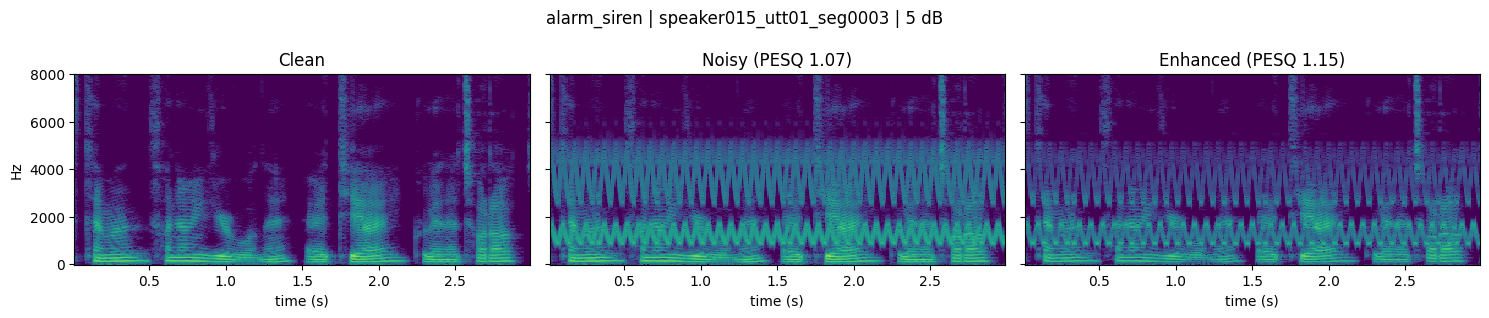

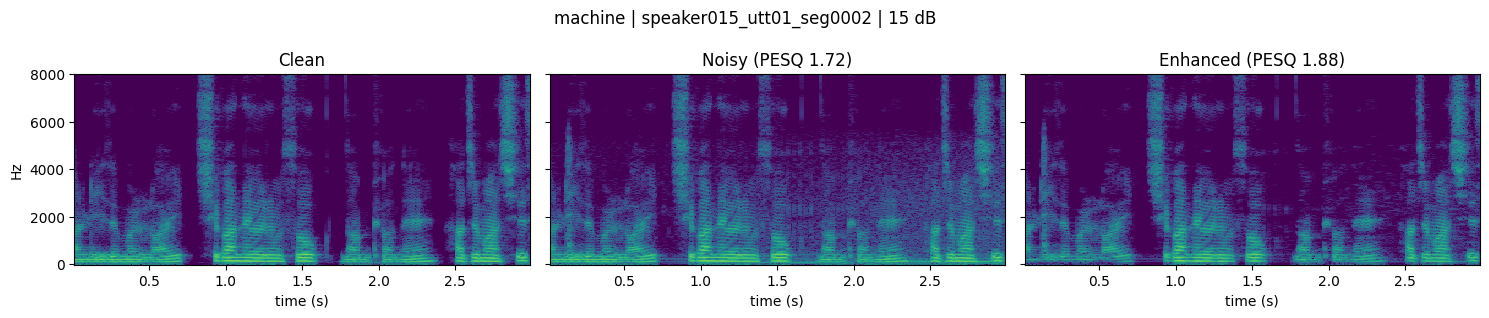

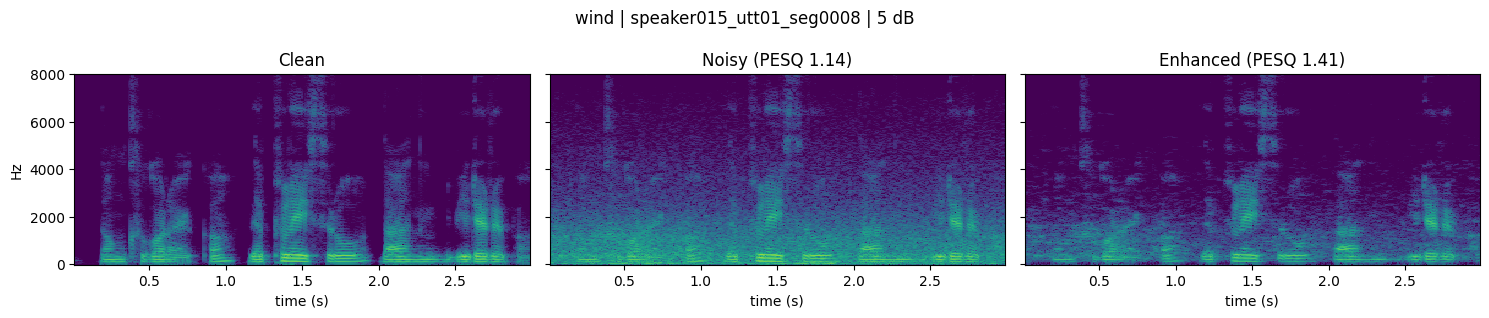

In [ ]:
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

def show_spec(row_filter, title):
    row = validation.loc[row_filter].iloc[0]
    clean, noisy = read_validation_pair(row)
    enh = np.clip(dn.denoise(noisy, SR), -1, 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2), sharey=True)
    for ax, (name, sig) in zip(axes, [("Clean", clean), ("Noisy", noisy), ("Enhanced", enh)]):
        f, t, S = spectrogram(sig, fs=SR, nperseg=512, noverlap=384)
        ax.pcolormesh(t, f, 10 * np.log10(S + 1e-12), shading="auto", vmin=-100, vmax=-20)
        ax.set_title(f"{name} (PESQ {safe_pesq(clean, sig):.2f})" if name != "Clean" else name)
        ax.set_xlabel("time (s)")
    axes[0].set_ylabel("Hz")
    fig.suptitle(f"{title} | {row.segment_id} | {row.target_snr_db:g} dB")
    plt.tight_layout(); plt.show()

show_spec(validation["noise_category"].eq("alarm_siren"), "alarm_siren")
show_spec(validation["noise_category"].eq("machine"), "machine")
show_spec(validation["noise_category"].eq("wind"), "wind")

In [ ]:
import shutil, subprocess
from pathlib import Path

shutil.rmtree("input_test", ignore_errors=True); shutil.rmtree("output_test", ignore_errors=True)
os.makedirs("input_test")
for pth in validation["noisy_path"]:
    shutil.copy(pth, "input_test/")

print(subprocess.run(["python", "denoise.py", "--input_dir", "input_test", "--output_dir", "output_test"],
                     capture_output=True, text=True))

scores, bad = [], 0
for row in validation.itertuples(index=False):
    name = Path(row.noisy_path).name
    clean, _ = read_validation_pair(row)
    x, sr_i = sf.read(f"input_test/{name}")
    y, sr_o = sf.read(f"output_test/{name}")
    if x.shape != y.shape or sr_i != sr_o:
        bad += 1
    scores.append(safe_pesq(clean, y))
print(f"입출력 형식 불일치: {bad}건 | CLI 출력 기준 평균 WB-PESQ = {np.mean(scores):.3f}")

CompletedProcess(args=['python', 'denoise.py', '--input_dir', 'input_test', '--output_dir', 'output_test'], returncode=0, stdout='', stderr='')
입출력 형식 불일치: 0건 | CLI 출력 기준 평균 WB-PESQ = 1.777


# 8-2. 상한 진단 (클로드)

In [8]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge
%pip install -q pesq==0.0.4 soundfile

import os, json, importlib
import numpy as np, pandas as pd, soundfile as sf
from IPython.display import display
from pesq import pesq
from tqdm.auto import tqdm
from multiprocessing import Pool

SR = 16_000
validation = pd.read_csv("validation/samples.csv")

def read_validation_pair(row):
    clean, _ = sf.read(row.clean_path, dtype="float64")
    noisy, _ = sf.read(row.noisy_path, dtype="float64")
    return clean, noisy

assert os.path.exists("denoise.py") and os.path.exists("best_params.json"), "denoise.py / best_params.json이 폴더에 없어요"
import denoise as dn
importlib.reload(dn)
print("불러온 파라미터: hp_hz", dn.DEFAULTS["hp_hz"], "| n_fft", dn.DEFAULTS["n_fft"], "| tonal_db", dn.DEFAULTS["tonal_db"])

def snr_db(ref, x):
    return 10 * np.log10(np.sum(ref**2) / max(np.sum((ref - x)**2), 1e-12))

def safe_pesq(ref, deg):
    try:
        return pesq(SR, ref, deg, "wb")
    except Exception:
        return 1.04

def eval_cascade(params=None, rows=validation, verbose=True):
    params = params or {}
    recs = []
    for row in tqdm(rows.itertuples(index=False), total=len(rows), disable=not verbose):
        clean, noisy = read_validation_pair(row)
        enh = np.clip(dn.denoise(noisy, SR, **params), -1, 1)
        recs.append({
            "noise_category": row.noise_category, "target_snr_db": row.target_snr_db,
            "Noisy PESQ": safe_pesq(clean, noisy), "PESQ": safe_pesq(clean, enh),
            "Noisy SNR": snr_db(clean, noisy), "SNR": snr_db(clean, enh),
        })
    return pd.DataFrame(recs)

cas = eval_cascade()
cas["PESQ Gain"] = cas["PESQ"] - cas["Noisy PESQ"]
print(f"복원 확인: 평균 WB-PESQ {cas['PESQ'].mean():.4f}  (1.7772 근처여야 정상)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge
불러온 파라미터: hp_hz 100.0 | n_fft 640 | tonal_db 18.0


  0%|          | 0/164 [00:00<?, ?it/s]

복원 확인: 평균 WB-PESQ 1.7772  (1.7772 근처여야 정상)


In [9]:
from scipy.signal import butter, sosfiltfilt, stft, istft
from scipy.ndimage import gaussian_filter1d

pos = np.random.default_rng(0).choice(len(validation), 80, replace=False)
vsub = validation.iloc[pos]
p0 = dict(dn.DEFAULTS)

def _stft(x):  return stft(x, fs=SR, window="hann", nperseg=int(p0["n_fft"]), noverlap=int(p0["n_fft"]) - int(p0["hop"]))[2]
def _istft(Z, n):
    y = istft(Z, fs=SR, window="hann", nperseg=int(p0["n_fft"]), noverlap=int(p0["n_fft"]) - int(p0["hop"]))[1][:n]
    return np.pad(y, (0, n - len(y))) if len(y) < n else y

_orig_psd = dn._noise_psd
def run_oracle_psd(mode):
    out = []
    try:
        for row in tqdm(vsub.itertuples(index=False), total=len(vsub), desc=mode):
            clean, noisy = read_validation_pair(row)
            nz = noisy - clean
            if p0["hp_hz"] > 0:
                nz = sosfiltfilt(butter(4, p0["hp_hz"], btype="highpass", fs=SR, output="sos"), nz)
            Pn = np.abs(_stft(nz)) ** 2
            if mode == "평균 PSD":
                Nor = np.repeat(Pn.mean(axis=1, keepdims=True), Pn.shape[1], axis=1)
            else:
                Nor = gaussian_filter1d(Pn, 10, axis=1, mode="nearest")
            Nor = np.maximum(Nor, 1e-14)
            dn._noise_psd = lambda P, p, Nor=Nor: Nor
            out.append(safe_pesq(clean, np.clip(dn.denoise(noisy, SR), -1, 1)))
    finally:
        dn._noise_psd = _orig_psd
    return float(np.mean(out))

def run_ideal_wiener():
    out = []
    for row in tqdm(vsub.itertuples(index=False), total=len(vsub), desc="ideal Wiener"):
        clean, noisy = read_validation_pair(row)
        S, Nn, Y = _stft(clean), _stft(noisy - clean), _stft(noisy)
        G = np.abs(S) ** 2 / (np.abs(S) ** 2 + np.abs(Nn) ** 2 + 1e-14)
        out.append(safe_pesq(clean, np.clip(_istft(Y * G, len(noisy)), -1, 1)))
    return float(np.mean(out))

diag = {
    "현재 (같은 80쌍)": cas["PESQ"].iloc[pos].mean(),
    "오라클 잡음 PSD (클립 평균)": run_oracle_psd("평균 PSD"),
    "오라클 잡음 PSD (시변)": run_oracle_psd("시변 PSD"),
    "이상적 Wiener 마스크": run_ideal_wiener(),
}
display(pd.Series(diag, name="Val PESQ (80쌍)").round(3))

top6 = ["machine", "wind", "alarm_siren", "aircraft_cockpit", "broadband_noise", "traffic_vehicle"]
display(cas[cas.noise_category.isin(top6)].pivot_table(
    index="noise_category", columns="target_snr_db", values="PESQ", aggfunc="mean").loc[top6].round(2))

평균 PSD:   0%|          | 0/80 [00:00<?, ?it/s]

시변 PSD:   0%|          | 0/80 [00:00<?, ?it/s]

ideal Wiener:   0%|          | 0/80 [00:00<?, ?it/s]

,Val PESQ (80쌍)
현재 (같은 80쌍),1.747
오라클 잡음 PSD (클립 평균),1.846
오라클 잡음 PSD (시변),1.956
이상적 Wiener 마스크,3.636


target_snr_db,0.0,5.0,10.0,15.0
noise_category,,,,
machine,1.12,1.30,1.73,2.24
wind,1.29,1.50,2.18,2.56
alarm_siren,1.16,1.51,1.73,2.01
aircraft_cockpit,1.09,1.32,1.49,1.95
broadband_noise,1.23,1.19,1.35,1.89
traffic_vehicle,NaN,1.32,1.29,2.28
